In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Loading the Taxis Dataset

In [11]:
df = sns.load_dataset("taxis")

### Check missing values

In [12]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

### Identify columns with missing data

In [13]:
missing = df.isnull().sum()
missing[missing > 0]

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

### Fill missing categorical values

In [16]:
df["payment"] = df["payment"].fillna(df["payment"].mode()[0])
df["pickup_zone"] = df["pickup_zone"].fillna(df["pickup_zone"].mode()[0])
df["dropoff_zone"] = df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0])
df["pickup_borough"] = df["pickup_borough"].fillna(df["pickup_borough"].mode()[0])
df["dropoff_borough"] = df["dropoff_borough"].fillna(df["dropoff_borough"].mode()[0])

### Line chart

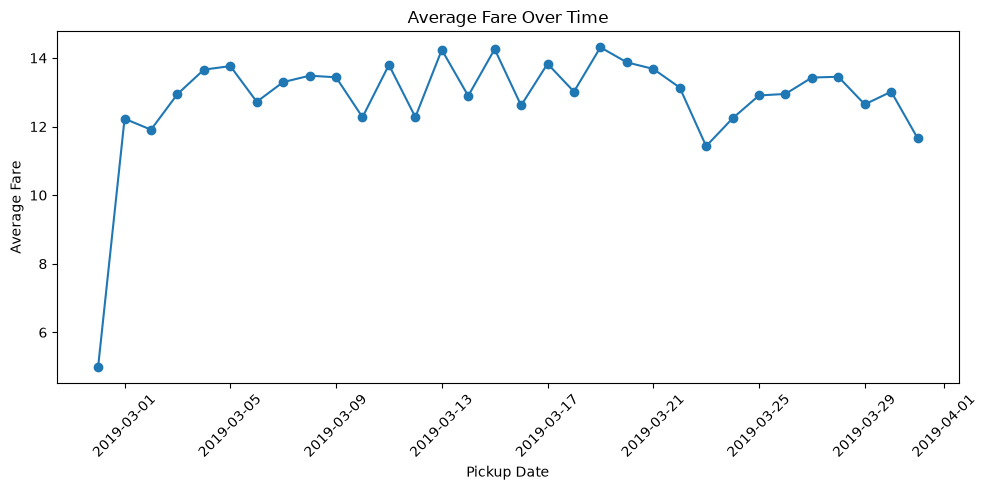

In [19]:
df["pickup"] = pd.to_datetime(df["pickup"])

daily_fare = df.groupby(df["pickup"].dt.date)["fare"].mean()

plt.figure(figsize=(10, 5))
plt.plot(daily_fare.index, daily_fare.values, marker="o")
plt.xlabel("Pickup Date")
plt.ylabel("Average Fare")
plt.title("Average Fare Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Bar chart

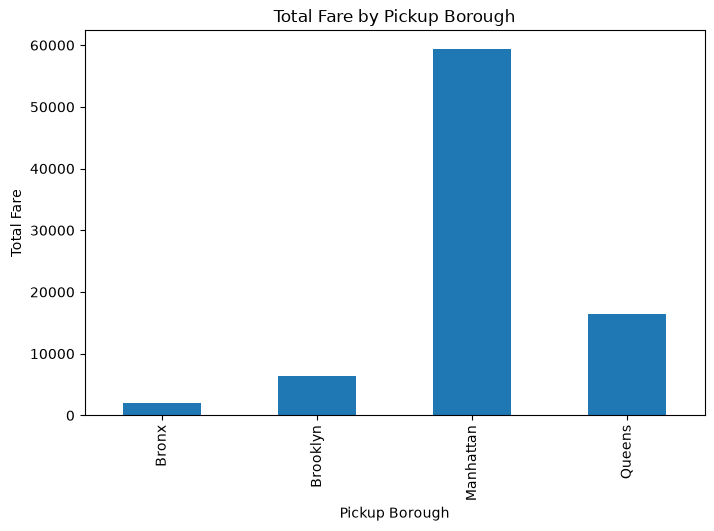

In [20]:
borough_fare = df.groupby("pickup_borough")["fare"].sum()

borough_fare.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")
plt.show()

### Pie chart

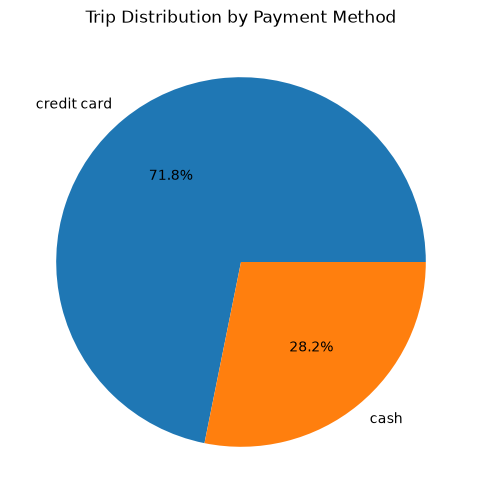

In [21]:
payment_count = df["payment"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(payment_count, labels=payment_count.index, autopct="%1.1f%%")
plt.title("Trip Distribution by Payment Method")
plt.show()

### Histogram

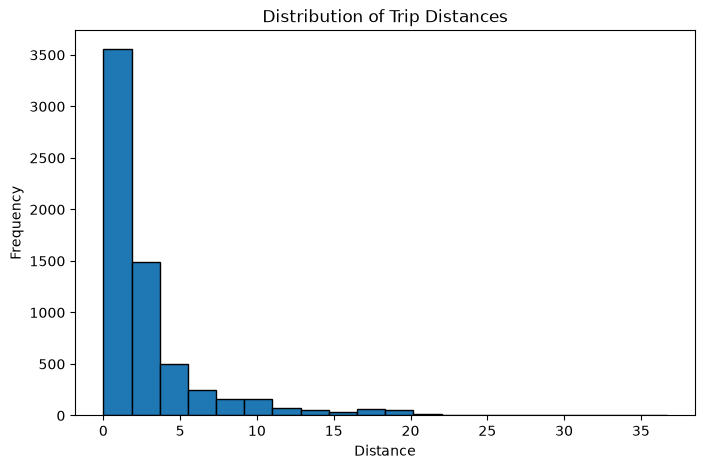

In [22]:
plt.figure(figsize=(8, 5))
plt.hist(df["distance"], bins=20, edgecolor="black")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Trip Distances")
plt.show()

### Box plot

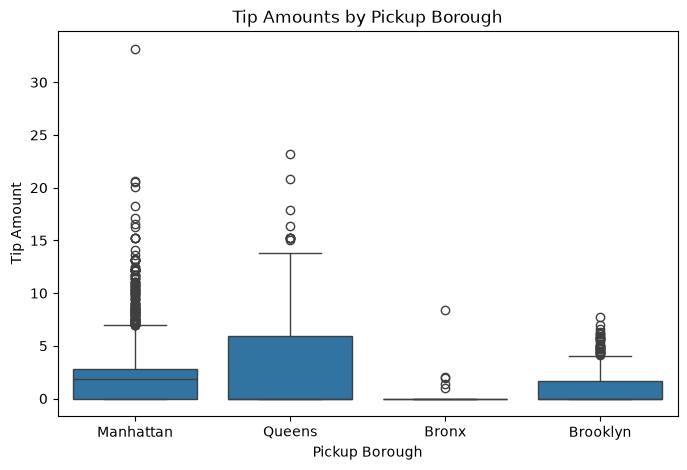

In [23]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="pickup_borough", y="tip", data=df)
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.title("Tip Amounts by Pickup Borough")
plt.show()

### Seaborn count plot

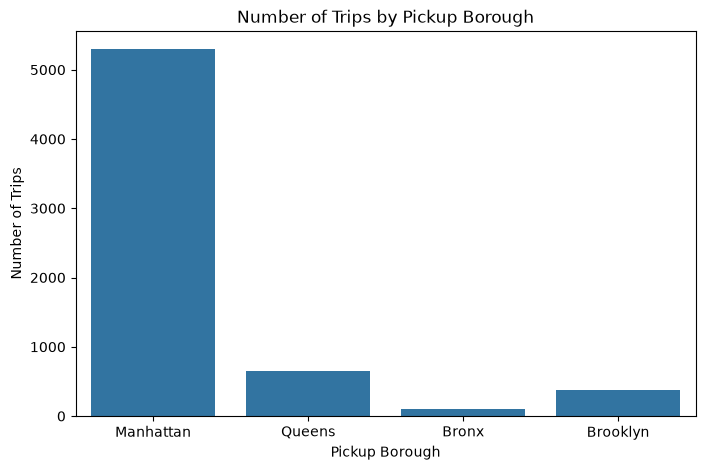

In [24]:
plt.figure(figsize=(8, 5))
sns.countplot(x="pickup_borough", data=df)
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Pickup Borough")
plt.show()

### Scatter Plot  

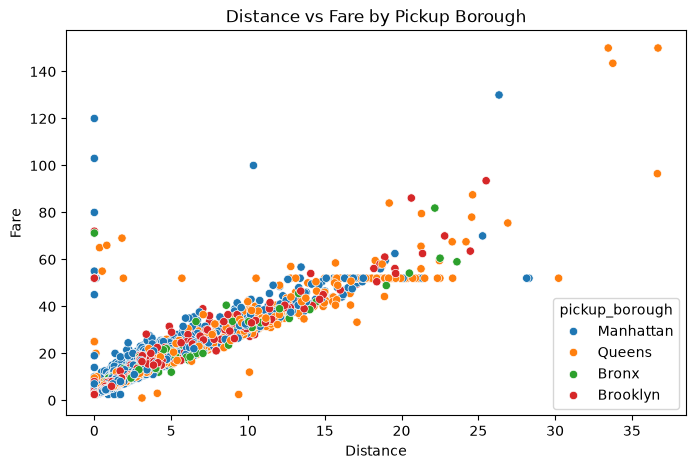

In [25]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="distance", y="fare", hue="pickup_borough", data=df)
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.title("Distance vs Fare by Pickup Borough")
plt.show()

### Heatmap

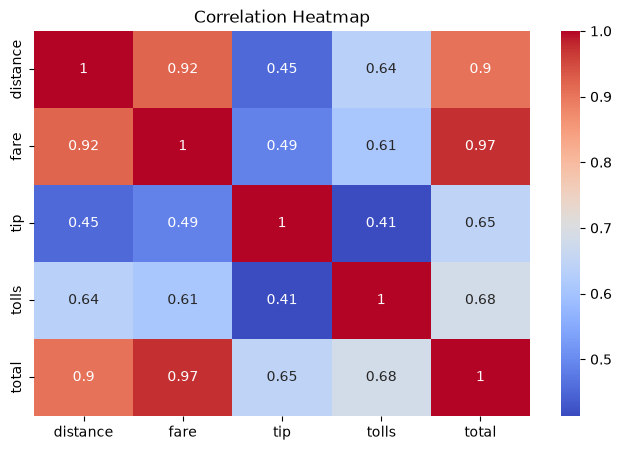

In [26]:
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

### Pair plot

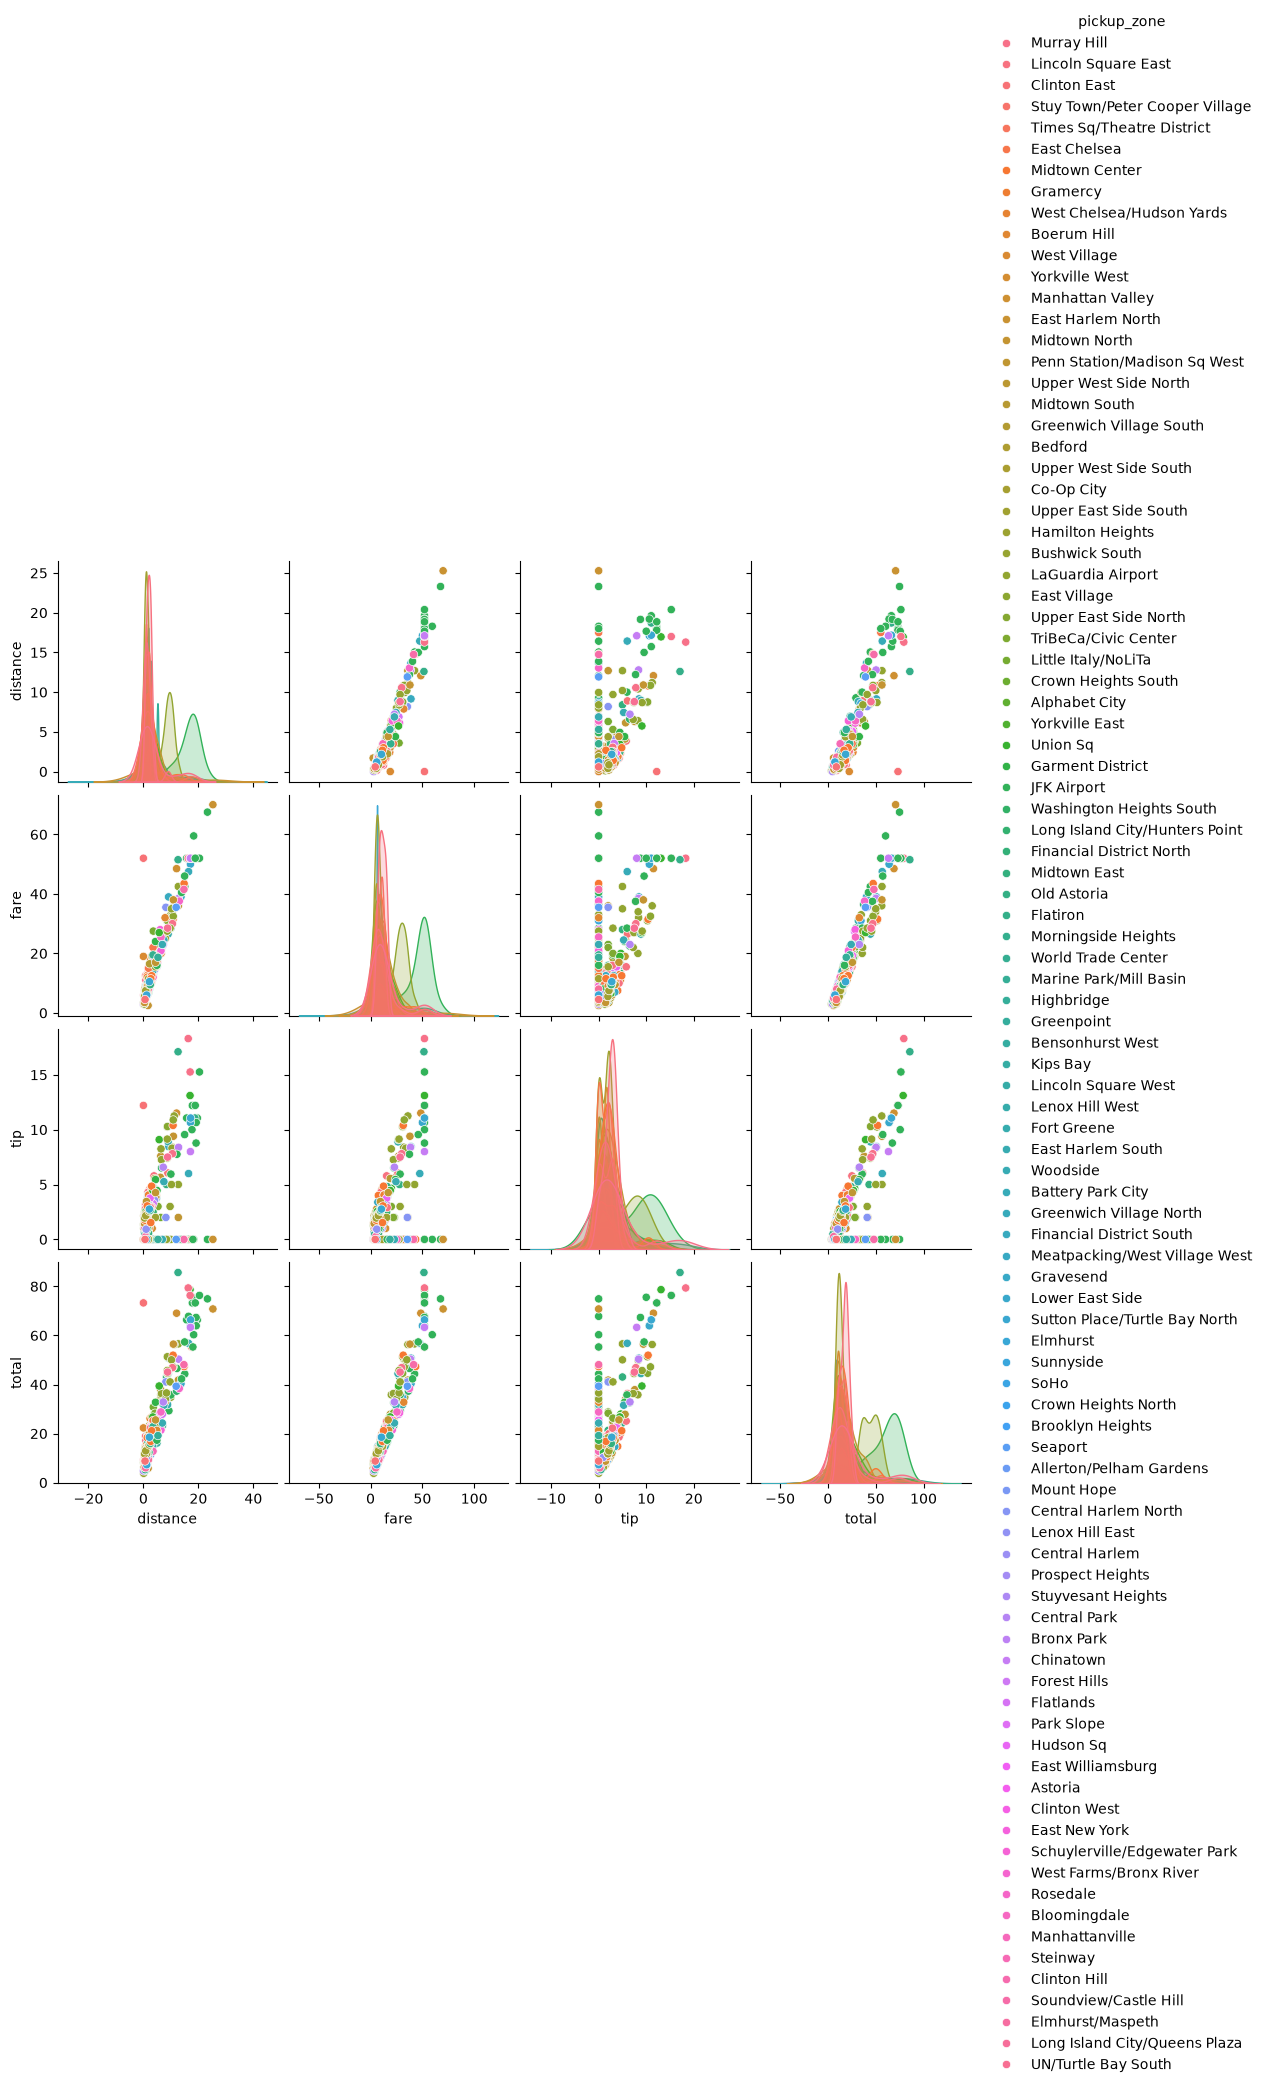

In [30]:
sns.pairplot(df.sample(500), vars=["distance", "fare", "tip", "total"], hue="pickup_zone")

### Violin plot

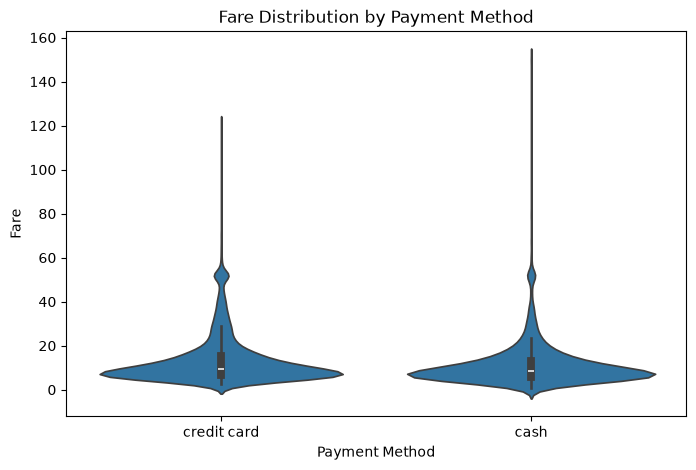

In [31]:
plt.figure(figsize=(8, 5))
sns.violinplot(x="payment", y="fare", data=df)
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.title("Fare Distribution by Payment Method")
plt.show()